# Sentiment Analysis using Neural Network, RNN, LSTM and GRU
## 1. Description: what this notebook does
**Task:** Perform sentiment analysis (positive / negative) on a dataset by building and comparing four deep-learning models, tuning their hyperparameters automatically, and identifying the best model and its best parameters.

| Step | What happens |
|---|---|
| 2 | Upload the dataset (CSV file with a text column and a label column) and prepare it |
| 3 | Model 1: **Neural Network** (feed-forward) with automatic hyperparameter tuning |
| 4 | Model 2: **RNN** (SimpleRNN) with automatic hyperparameter tuning |
| 5 | Model 3: **LSTM** with automatic hyperparameter tuning |
| 6 | Model 4: **GRU** with automatic hyperparameter tuning |
| 7 | Compare all four models and print the **most effective model with its best parameters** |

**How the tuning works:** for each model, several random combinations of hyperparameters are picked from predefined ranges (embedding size, hidden units, dropout, learning rate, batch size, optimizer). Each combination is trained and scored on a validation set. The best one is then tested once on unseen test data.

**How to run:** click *Runtime ▸ Run all* (tip: Runtime ▸ Change runtime type ▸ T4 GPU makes it faster). When Step 2 shows a *Choose Files* button, upload your CSV.

## 2. Upload the dataset
### 2.1 Imports and settings (including the predefined hyperparameter ranges)

In [12]:
import os, re, io, time, random, zipfile, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

MAX_VOCAB = 10000     # number of words kept
MAX_LEN   = 200       # words per review (longer reviews are cut)
EPOCHS    = 10        # max training epochs per trial (early stopping is used)
N_TRIALS  = 6         # hyperparameter combinations tested per model

SEARCH_SPACE = {      # predefined hyperparameter ranges
    "embedding_dim": [32, 64, 128],
    "units":         [32, 64, 128],
    "dropout":       [0.2, 0.3, 0.5],
    "learning_rate": [1e-2, 3e-3, 1e-3],
    "batch_size":    [32, 64],
    "optimizer":     ["adam", "rmsprop"],
}

### 2.2 Upload your CSV
* Keep `USE_SAMPLE_DATASET = False` and click **Choose Files** to upload your own CSV (one text column + one label column; labels 0/1 or positive/negative).
* No dataset yet? Set `USE_SAMPLE_DATASET = True` to use a built-in movie-review dataset (2,000 reviews).
* Column names are detected automatically. If wrong, type them into `TEXT_COL` and `LABEL_COL`.

In [18]:
USE_SAMPLE_DATASET = True
TEXT_COL, LABEL_COL = "", ""      # optional, e.g. TEXT_COL = "review", LABEL_COL = "sentiment"

def clean(t):
    t = re.sub(r"<.*?>", " ", str(t).lower())
    t = re.sub(r"[^a-z' ]+", " ", t)
    return re.sub(r"\s+", " ", t).strip()

def map_labels(s):
    if not pd.api.types.is_numeric_dtype(s):
        m = {"positive": 1, "pos": 1, "1": 1, "negative": 0, "neg": 0, "0": 0}
        out = s.astype(str).str.lower().str.strip().map(m)
        if out.isna().any():
            raise ValueError(f"Labels must be 0/1 or positive/negative. Found: {list(s.unique())[:10]}")
        return out
    return s.astype(int)

def load_sample():
    if not os.path.isdir("movie_reviews"):
        url = "https://raw.githubusercontent.com/nltk/nltk_data/gh-pages/packages/corpora/movie_reviews.zip"
        zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())).extractall(".")
    rows = [(open(f"movie_reviews/{d}/{f}", encoding="latin-1").read(), lab)
            for lab, d in [(1, "pos"), (0, "neg")] for f in sorted(os.listdir(f"movie_reviews/{d}"))]
    return pd.DataFrame(rows, columns=["text", "label"])

if USE_SAMPLE_DATASET:
    df = load_sample()
else:
    from google.colab import files
    up = files.upload()                                   # <-- choose your CSV file here
    raw = pd.read_csv(io.BytesIO(next(iter(up.values()))), encoding_errors="replace")
    print("Columns found:", list(raw.columns))
    tc, lc = TEXT_COL, LABEL_COL
    if not tc or not lc:
        text_like = [c for c in raw.columns if not pd.api.types.is_numeric_dtype(raw[c])]
        tc = tc or max(text_like, key=lambda c: raw[c].astype(str).str.len().mean())
        lc = lc or [c for c in raw.columns if c != tc][-1]
    print(f"Using text column = '{tc}', label column = '{lc}'")
    df = pd.DataFrame({"text": raw[tc], "label": map_labels(raw[lc])}).dropna()

df["text"] = df["text"].map(clean)
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)
print(f"\nDataset: {len(df)} samples | positive = {int(df.label.sum())} | negative = {int(len(df) - df.label.sum())}")
df.head()


Dataset: 2000 samples | positive = 1000 | negative = 1000


,text,label
0,i guess that if a very wild bachelor party had...,0
1,with the abundance of trite recycled movies in...,1
2,as a hot shot defense attorney kevin lomax kea...,0
3,hedwig john cameron mitchell was born a boy na...,1
4,i've heard it called jaws with claws and that'...,0


### 2.3 Split into train / validation / test, and shared helper functions

In [19]:
X_tr, X_tmp, y_tr, y_tmp = train_test_split(df.text.values, df.label.values, test_size=0.30,
                                            stratify=df.label, random_state=SEED)
X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print(f"Train / Validation / Test = {len(X_tr)} / {len(X_val)} / {len(X_te)}")

to_t = lambda a: tf.constant(np.array(a, dtype=str).reshape(-1, 1))
X_tr, X_val, X_te = to_t(X_tr), to_t(X_val), to_t(X_te)
y_tr, y_val, y_te = [np.asarray(a, dtype="float32") for a in (y_tr, y_val, y_te)]

vec = layers.TextVectorization(max_tokens=MAX_VOCAB, output_sequence_length=MAX_LEN)
vec.adapt(X_tr)                                           # vocabulary from training data only

# the same random hyperparameter combinations are used for every model (fair comparison)
rng, seen, CONFIGS = random.Random(SEED), set(), []
while len(CONFIGS) < N_TRIALS:
    cfg = {k: rng.choice(v) for k, v in SEARCH_SPACE.items()}
    if tuple(cfg.values()) not in seen:
        seen.add(tuple(cfg.values())); CONFIGS.append(cfg)

def build_model(kind, hp):
    inp = layers.Input(shape=(1,), dtype=tf.string)
    x = vec(inp)
    x = layers.Embedding(MAX_VOCAB, hp["embedding_dim"], mask_zero=(kind != "NeuralNetwork"))(x)
    if kind == "NeuralNetwork":
        x = layers.GlobalAveragePooling1D()(x)
        x = layers.Dense(hp["units"], activation="relu")(x)
    elif kind == "RNN":  x = layers.SimpleRNN(hp["units"])(x)
    elif kind == "LSTM": x = layers.LSTM(hp["units"])(x)
    elif kind == "GRU":  x = layers.GRU(hp["units"])(x)
    x = layers.Dropout(hp["dropout"])(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    m = models.Model(inp, out)
    opt = optimizers.Adam if hp["optimizer"] == "adam" else optimizers.RMSprop
    m.compile(optimizer=opt(learning_rate=hp["learning_rate"], clipnorm=1.0),
              loss="binary_crossentropy", metrics=["accuracy"])
    return m

RESULTS, ALL_RUNS = {}, []

def tune_and_evaluate(kind):
    """Try every hyperparameter combination, keep the best on validation data, score it on test data."""
    best = None
    for i, hp in enumerate(CONFIGS, 1):
        tf.keras.backend.clear_session(); tf.random.set_seed(SEED)
        m = build_model(kind, hp); t0 = time.time()
        es = callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True)
        h = m.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=EPOCHS,
                  batch_size=hp["batch_size"], callbacks=[es], verbose=0)
        val_acc = max(h.history["val_accuracy"])
        ALL_RUNS.append({"model": kind, "trial": i, **hp, "val_accuracy": round(val_acc, 4)})
        print(f"trial {i}/{N_TRIALS}  val_acc = {val_acc:.4f}  ({time.time()-t0:.0f}s)  {hp}", flush=True)
        if best is None or val_acc > best["val"]:
            best = {"hp": hp, "val": val_acc, "model": m, "hist": h.history}
    pred = (best["model"].predict(X_te, verbose=0).ravel() >= 0.5).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(y_te, pred, average="binary", zero_division=0)
    RESULTS[kind] = {"Val Acc": round(best["val"], 4), "Test Acc": round(accuracy_score(y_te, pred), 4),
                     "Precision": round(p, 4), "Recall": round(r, 4), "F1": round(f1, 4),
                     "hp": best["hp"], "hist": best["hist"], "cm": confusion_matrix(y_te, pred)}
    r_ = RESULTS[kind]
    print("\n" + "-" * 60)
    print(f"{kind} RESULT  ->  Test accuracy = {r_['Test Acc']:.2%} | Precision = {r_['Precision']} | Recall = {r_['Recall']} | F1 = {r_['F1']}")
    print("Best hyperparameters:", r_["hp"])
    print("-" * 60)

def plot_history(kind):
    h = RESULTS[kind]["hist"]
    plt.figure(figsize=(6, 3.5))
    plt.plot(h["accuracy"], marker="o", label="train accuracy")
    plt.plot(h["val_accuracy"], marker="o", label="validation accuracy")
    plt.title(f"{kind}: training curve (best configuration)"); plt.xlabel("epoch"); plt.legend(); plt.show()

Train / Validation / Test = 1400 / 300 / 300


## 3. Neural Network
A simple **feed-forward network**: word embeddings are averaged over the review, then passed through a dense layer. It ignores word order, but it is fast and works well on small datasets.

*Architecture:* Embedding → Global Average Pooling → Dense(ReLU) → Dropout → Sigmoid output.

trial 1/6  val_acc = 0.7033  (6s)  {'embedding_dim': 128, 'units': 32, 'dropout': 0.2, 'learning_rate': 0.001, 'batch_size': 64, 'optimizer': 'adam'}
trial 2/6  val_acc = 0.7133  (8s)  {'embedding_dim': 32, 'units': 32, 'dropout': 0.5, 'learning_rate': 0.01, 'batch_size': 32, 'optimizer': 'rmsprop'}
trial 3/6  val_acc = 0.7033  (4s)  {'embedding_dim': 32, 'units': 32, 'dropout': 0.2, 'learning_rate': 0.01, 'batch_size': 32, 'optimizer': 'adam'}
trial 4/6  val_acc = 0.7133  (6s)  {'embedding_dim': 128, 'units': 32, 'dropout': 0.5, 'learning_rate': 0.001, 'batch_size': 64, 'optimizer': 'adam'}
trial 5/6  val_acc = 0.6900  (7s)  {'embedding_dim': 64, 'units': 128, 'dropout': 0.3, 'learning_rate': 0.01, 'batch_size': 32, 'optimizer': 'rmsprop'}
trial 6/6  val_acc = 0.6967  (4s)  {'embedding_dim': 64, 'units': 64, 'dropout': 0.2, 'learning_rate': 0.01, 'batch_size': 64, 'optimizer': 'adam'}

------------------------------------------------------------
NeuralNetwork RESULT  ->  Test accuracy

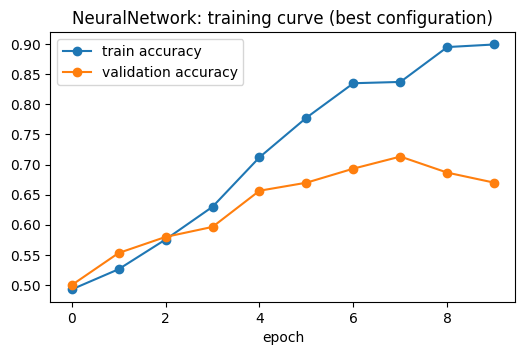

In [20]:
tune_and_evaluate("NeuralNetwork")
plot_history("NeuralNetwork")

## 4. RNN (Recurrent Neural Network)
A **SimpleRNN** reads the review word by word and keeps a hidden state. It captures word order, but it struggles with long text because early words are forgotten (vanishing gradient).

*Architecture:* Embedding → SimpleRNN → Dropout → Sigmoid output.

trial 1/6  val_acc = 0.5200  (37s)  {'embedding_dim': 128, 'units': 32, 'dropout': 0.2, 'learning_rate': 0.001, 'batch_size': 64, 'optimizer': 'adam'}
trial 2/6  val_acc = 0.5233  (99s)  {'embedding_dim': 32, 'units': 32, 'dropout': 0.5, 'learning_rate': 0.01, 'batch_size': 32, 'optimizer': 'rmsprop'}
trial 3/6  val_acc = 0.5300  (94s)  {'embedding_dim': 32, 'units': 32, 'dropout': 0.2, 'learning_rate': 0.01, 'batch_size': 32, 'optimizer': 'adam'}
trial 4/6  val_acc = 0.5100  (44s)  {'embedding_dim': 128, 'units': 32, 'dropout': 0.5, 'learning_rate': 0.001, 'batch_size': 64, 'optimizer': 'adam'}
trial 5/6  val_acc = 0.5367  (90s)  {'embedding_dim': 64, 'units': 128, 'dropout': 0.3, 'learning_rate': 0.01, 'batch_size': 32, 'optimizer': 'rmsprop'}
trial 6/6  val_acc = 0.5167  (36s)  {'embedding_dim': 64, 'units': 64, 'dropout': 0.2, 'learning_rate': 0.01, 'batch_size': 64, 'optimizer': 'adam'}

------------------------------------------------------------
RNN RESULT  ->  Test accuracy = 5

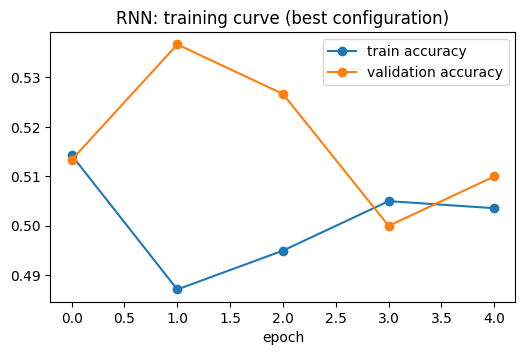

In [9]:
tune_and_evaluate("RNN")
plot_history("RNN")

## 5. LSTM (Long Short-Term Memory)
An **LSTM** adds gates and a memory cell, so it can remember important words over long reviews and avoids the RNN's forgetting problem.

*Architecture:* Embedding → LSTM → Dropout → Sigmoid output.

trial 1/6  val_acc = 0.6500  (5s)  {'embedding_dim': 128, 'units': 32, 'dropout': 0.2, 'learning_rate': 0.001, 'batch_size': 64, 'optimizer': 'adam'}
trial 2/6  val_acc = 0.5367  (9s)  {'embedding_dim': 32, 'units': 32, 'dropout': 0.5, 'learning_rate': 0.01, 'batch_size': 32, 'optimizer': 'rmsprop'}
trial 3/6  val_acc = 0.5300  (8s)  {'embedding_dim': 32, 'units': 32, 'dropout': 0.2, 'learning_rate': 0.01, 'batch_size': 32, 'optimizer': 'adam'}
trial 4/6  val_acc = 0.6467  (7s)  {'embedding_dim': 128, 'units': 32, 'dropout': 0.5, 'learning_rate': 0.001, 'batch_size': 64, 'optimizer': 'adam'}
trial 5/6  val_acc = 0.5333  (6s)  {'embedding_dim': 64, 'units': 128, 'dropout': 0.3, 'learning_rate': 0.01, 'batch_size': 32, 'optimizer': 'rmsprop'}
trial 6/6  val_acc = 0.5400  (4s)  {'embedding_dim': 64, 'units': 64, 'dropout': 0.2, 'learning_rate': 0.01, 'batch_size': 64, 'optimizer': 'adam'}

------------------------------------------------------------
LSTM RESULT  ->  Test accuracy = 63.67%

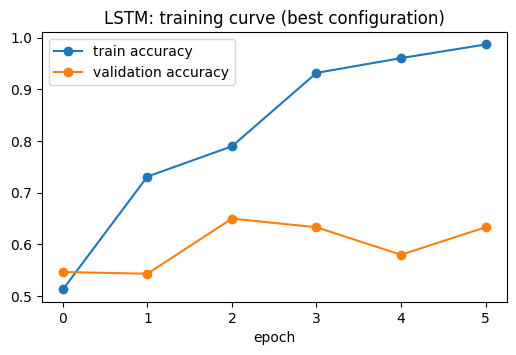

In [11]:
tune_and_evaluate("LSTM")
plot_history("LSTM")

## 6. GRU (Gated Recurrent Unit)
A **GRU** is a lighter version of the LSTM with fewer gates. It is faster to train and often performs similarly.

*Architecture:* Embedding → GRU → Dropout → Sigmoid output.

trial 1/6  val_acc = 0.5167  (5s)  {'embedding_dim': 128, 'units': 32, 'dropout': 0.2, 'learning_rate': 0.001, 'batch_size': 64, 'optimizer': 'adam'}
trial 2/6  val_acc = 0.5167  (6s)  {'embedding_dim': 32, 'units': 32, 'dropout': 0.5, 'learning_rate': 0.01, 'batch_size': 32, 'optimizer': 'rmsprop'}
trial 3/6  val_acc = 0.5233  (7s)  {'embedding_dim': 32, 'units': 32, 'dropout': 0.2, 'learning_rate': 0.01, 'batch_size': 32, 'optimizer': 'adam'}
trial 4/6  val_acc = 0.5867  (8s)  {'embedding_dim': 128, 'units': 32, 'dropout': 0.5, 'learning_rate': 0.001, 'batch_size': 64, 'optimizer': 'adam'}
trial 5/6  val_acc = 0.5333  (8s)  {'embedding_dim': 64, 'units': 128, 'dropout': 0.3, 'learning_rate': 0.01, 'batch_size': 32, 'optimizer': 'rmsprop'}
trial 6/6  val_acc = 0.5267  (6s)  {'embedding_dim': 64, 'units': 64, 'dropout': 0.2, 'learning_rate': 0.01, 'batch_size': 64, 'optimizer': 'adam'}

------------------------------------------------------------
GRU RESULT  ->  Test accuracy = 55.33% 

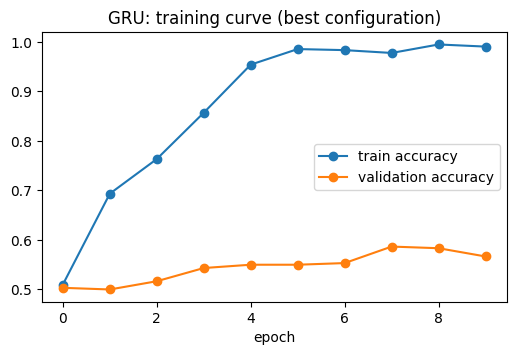

In [14]:
tune_and_evaluate("GRU")
plot_history("GRU")

## 7. Final comparison: which model is the most efficient?
All four models are compared on the **same unseen test data**, each using its own best tuned hyperparameters. The winner is the model with the highest test accuracy (ties broken by F1-score).

FINAL COMPARISON (best tuned configuration of each model, on unseen test data)
     Val Acc  Test Acc  Precision  Recall      F1
GRU   0.5867    0.5533     0.5476  0.6133  0.5786

MOST EFFICIENT MODEL : GRU
Test accuracy        : 55.33%   |   F1-score: 0.5786
BEST HYPERPARAMETERS :
    embedding_dim  = 128
    units          = 32
    dropout        = 0.5
    learning_rate  = 0.001
    batch_size     = 64
    optimizer      = adam
Ranking: GRU (55.3%)


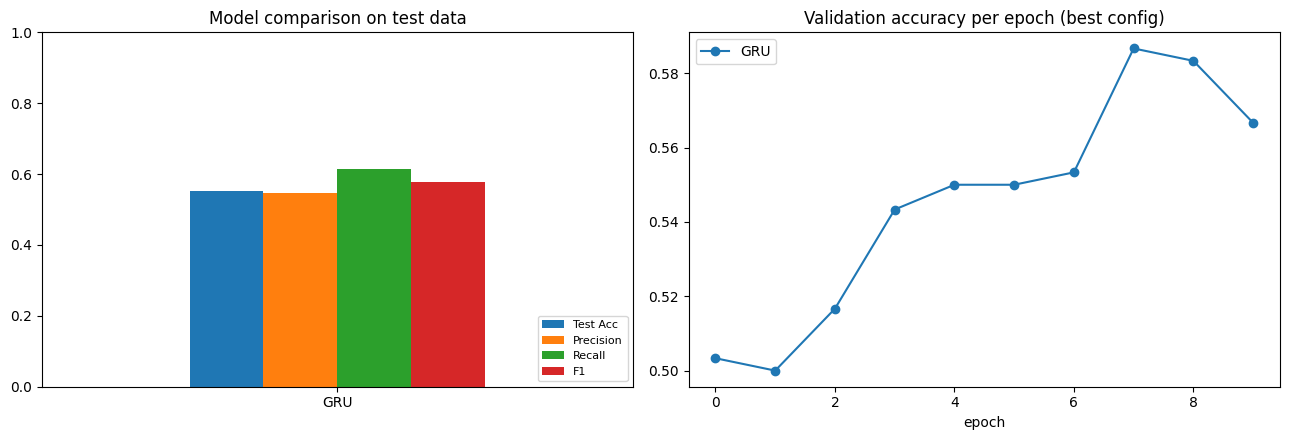

In [17]:
summary = pd.DataFrame({k: {m: v[m] for m in ["Val Acc", "Test Acc", "Precision", "Recall", "F1"]}
                        for k, v in RESULTS.items()}).T.sort_values(["Test Acc", "F1"], ascending=False)
winner = summary.index[0]

print("=" * 70)
print("FINAL COMPARISON (best tuned configuration of each model, on unseen test data)")
print("=" * 70)
print(summary.to_string())
print("\n" + "=" * 70)
print(f"MOST EFFICIENT MODEL : {winner}")
print(f"Test accuracy        : {summary.loc[winner, 'Test Acc']:.2%}   |   F1-score: {summary.loc[winner, 'F1']:.4f}")
print("BEST HYPERPARAMETERS :")
for k, v in RESULTS[winner]["hp"].items():
    print(f"    {k:14s} = {v}")
print("=" * 70)
print("Ranking:", " > ".join(f"{m} ({summary.loc[m, 'Test Acc']:.1%})" for m in summary.index))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
summary[["Test Acc", "Precision", "Recall", "F1"]].plot(kind="bar", ax=ax[0], rot=0, ylim=(0, 1))
ax[0].set_title("Model comparison on test data"); ax[0].legend(loc="lower right", fontsize=8)
for k, v in RESULTS.items():
    ax[1].plot(v["hist"]["val_accuracy"], marker="o", label=k)
ax[1].set_title("Validation accuracy per epoch (best config)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig("model_comparison.png", dpi=140); plt.show()